# Tutorial: `Pipeline` wrapper

## Introduction

This tutorial explains the library's object model and the authors' construction convention. 

You will discover components, build and edit a computation graph, run a small optimization, and inspect its retained results. 

> Remark:
> The companion notebooks are 
> - [Reader](reader_tutorial.ipynb), 
> - [Orchestrator](orchestrator_tutorial.ipynb),
> - [Methodology](methodology_tutorial.ipynb).


### Library abstraction

The library separates three responsibilities:

- construction (`core.builder`) defines and validates the computation;
- execution (`optimization.engine`) runs the built computation;
- reading and analysis (`optimization.saving` and `analysis`) expose persisted results.

The wrapper combines their public entry points. It does not implement numerical algorithms.

These responsibilities produce three related structures:

| Structure | Meaning | Identity |
| --- | --- | --- |
| Declaration | The pipeline structure and immutable constructor snapshots collected by the editable builder | A stable `node_id` identifies each declared step placement |
| Execution | Fresh `Step` instances created from the declaration and initialized during `build()` | Each instance retains its placement’s `node_id`; one node can be invoked many times during a run |
| Candidate lineage | Candidate occurrences and parent relations recorded during `run()` | Run-local candidate, batch and evaluation IDs identify data and events |

#### Steps in the declaration and execution

A `Step` is the library’s unit of computation. In the **declaration**, it specifies a component, its parameters, and if it is composite - its child steps. During `build()`, the builder creates and initializes executable `Step` instances from that declaration. During `run()`, those instances receive and return batches according to their contracts.

A *leaf `Step`* performs an operation on a batch. For example:
- a filter selects rows, 
- a mutation generates candidates, 
- an oracle evaluates sequences.

A *composite `Step`* controls how its child steps are called:
- `Flow` passes each child’s output to the next child;
- `Loop` feeds the body’s output into its next iteration;
- `Parallel` gives each branch the same input;
- `LocalEnumeration` keeps walker trajectories separate from emitted mutations.

Every declared step placement has a stable **node ID**, whether it is a leaf or a composite. Child placements have their own node IDs. The ID links a declared placement to the corresponding executable node. If that node is invoked repeatedly, for example, in a loop—each invocation still refers to the same `node_id`; an execution ID distinguishes the individual invocation.

A constructor such as `ps.filters.CandidateSubset(count=3)` creates a real `Step` instance with parameters and methods. “Lightweight” means that constructing it has not loaded model weights or processed candidates. `build()` prepares the executable instances and initializes their numerical resources; `run()` processes the input data.


### Tutorial dependencies

Run the setup commands from the repository root. These examples explicitly use CPU.

```bash
uv sync --extra cpu
bash assets/scripts/downloads/hydraAMP/download_hydramp_model.sh
bash assets/scripts/downloads/apex/download_apex_models_default.sh
```

> Remarks:
> - The standard `article_25` HydrAMP weights are already bundled, its script checks their presence. 
> - The APEX script downloads the `default` ensemble when missing. 
> - The wrapper examples do not require a peptide dataset or training. Select the installed environment as the notebook kernel. 
> - All computation below uses the public library. seeds and small limits are explicit.

> Remark:
> You can select the appropriate supported CUDA extra instead of `cpu` when needed.

### Cells

The first cell imports the public namespaces and lists component categories. The next cell narrows the list and inspects defaults, internal strategies and technical field contracts before constructing a pipeline.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory             # to avoid creating local files
from IPython.display import display

from pep_compass import Pipeline, PipelineBuilder
import pep_compass.autoencoder as ae
import pep_compass.steps as ps                      # ps - PipelineSteps

pipeline = Pipeline()
pipeline.describe()  # USAGE: automatic formatted display; weights are not loaded.

/home/max/repositories/pep-compass/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


component,strategy,description,internal_stages
filters,Deduplicate,Keep the first candidate for every configured identity key.,
filters,CandidateSubset,Select at most a fixed number of candidates from the complete batch.,
filters,Levenshtein,Keep sequences within an inclusive edit radius of a reference.,
filters,SequenceLength,Keep sequences whose lengths lie in an inclusive interval.,
filters,TrustRegion,Retain candidates within the current objective-specific trust region.,
filters,TrustRegionUpdate,Update center and radius from scores already attached by an oracle.,
filters,Robot,Select a diverse batch using GP expected improvement. The selector reads observations collected by an oracle from,
filters,RandomMutationPool,Apply random proposals or random ranking to each MUTANG parent pool.,
filters,Ranked,Compose one score function with one score-based selection rule.,"scoring, selection"
filters,Lams,Compose LAMS scoring and threshold selection without a marker subclass.,


In [2]:
pipeline.describe("filters", display="pd")                                              # USAGE: return a reusable pandas DataFrame.
pipeline.describe_component(ps.filters.CandidateSubset)                                 # Required values, constructor defaults and help.
pipeline.describe_component(ps.walkers.Sorbes(), technical=True)                        # Resolved internal stages and field contract.
raw = pipeline.describe_component(ps.filters.CandidateSubset(count=3), display="raw")
assert raw["configuration"]["count"] == 3

## Constructing and editing pipelines

### Relation between components (`builder`)

The wrapper owns a mutable `PipelineBuilder`. The builder stores an **immutable** `PipelineSchema` made of `NodeSpec` snapshots. **Editing replaces that snapshot, it does not mutate an already returned executable graph**. The source component is a genuine Python object, while its `NodeSpec` stores its import target, constructor arguments, child declarations and stable placement ID. It stores no model weights.

```text
ps.filters.CandidateSubset(count=3)          real, lightweight Step instance
    -> builder.add(component)               snapshot constructor + assign node_id
    -> PipelineSchema / NodeSpec            immutable declaration
    -> builder.build()                      validate, instantiate, initialize
    -> ExecutablePipeline                   prepared root Flow and shared model
```

For example, 
- `[CandidateSubset(count=3), Hydrophobicity()]` becomes a root `Flow` whose two children are fresh instances of those actual classes. 
- `node.instantiate()` calls the saved constructor and binds the placement ID. 
- `root.initialize(autoencoder)` traverses nested components and initializes numerical resources.
-  Built-in oracle weights are loaded at initialization; constructors alone do not load them. 
-  Validation also creates temporary lightweight instances to inspect contracts, without initializing models.

See [PipelineBuilder](../../src/pep_compass/core/builder/builder.py), [NodeSpec](../../src/pep_compass/data_schemas/graph.py), and [Step](../../src/pep_compass/steps/base.py).

### Validation

`validate()` checks declarations without running candidates or loading weights. `build()` runs that validation before resource initialization. Success currently returns `[]`; invalid declarations raise `ValueError` or `TypeError`.

1. Check closed construction scopes and unique, non-empty node IDs. Instantiate lightweight declarations and check that graph children are Steps.
2. Resolve each Step's required fields, produced fields, invalidated prefixes and partial-field permissions. Reject different predictor configurations using the same objective field.
3. Propagate field availability symbolically. For a leaf, available fields change as `F_next = (F minus invalidated fields) union produced fields`. Maintain both fields guaranteed for every row and fields present in at least part of a batch. `optional_fields` permits the latter representation for a declared required input.
4. Compose sequential transfers in order. At parallel joins, intersect full-row guarantees and combine partial presence; a branch cannot promise a fully available field merely because another branch produces it.
5. For repeated bodies, check that required inputs survive or are reproduced on the feedback edge. The transfer `(F intersect K) union P` is idempotent, so this check does not simulate every configured iteration. A zero-iteration loop skips its body requirements.
6. For `LocalEnumeration`, account for its supplied center/trajectory fields, walker -> mutation -> local-filter order, and removed transient geometry fields. Shared-geometry MUTANG must be inside a compatible local enumeration.

This is structural and field-flow validation, not a prediction of numerical results. It does not prove scientific correctness, check model files in advance, or run inference. Candidate-count estimation is separate from field validation; a declaration's output bound is not a measurement of oracle evaluations. The implementation is [builder.validation](../../src/pep_compass/core/builder/validation/__init__.py).

### Cells

The next three cells construct the same component order by incremental wrapper edits, a complete component list, and a standalone builder. Each displays the declaration before `build()` and the prepared graph afterwards. The editing cell then demonstrates stable IDs across insert/replace/remove operations. A new build leaves previous executable graphs independent.

`show()` displays SVG. `to_schema()` returns the schema object; `text`, `json`, `mermaid` and `svg` select representations of the declaration. Mermaid is diagram source requiring a compatible renderer; SVG is a ready image. None executes the pipeline.

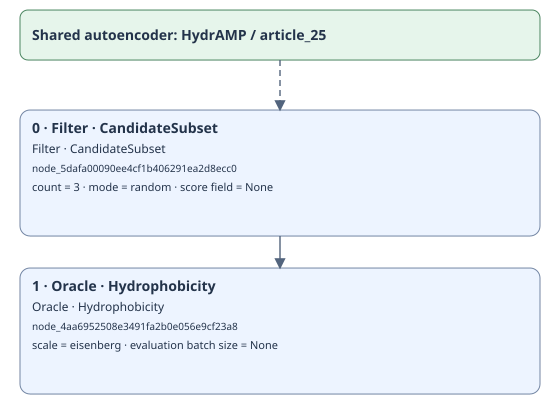

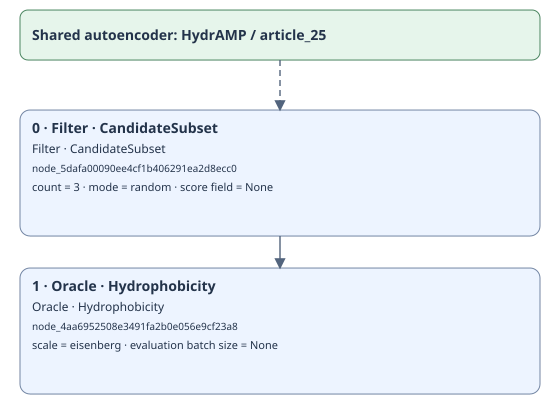

In [16]:
# USAGE: 1. Add concrete components incrementally.
## Define 
incremental = Pipeline(autoencoder=ae.HydrAMP(jacobian_mode="approx"))              # create Pipeline with given autoencoder
selection_id = incremental.add_component(ps.filters.CandidateSubset(count=3))       # add component and assign return value (node_id of graph element) 
incremental.add_component(ps.oracles.Hydrophobicity())                              # add component
## Display graph before build
display(incremental.show())
## Build object 
compiled_incremental = incremental.build()
## Display builded object 
display(compiled_incremental.show())

## assert that node_id (ids of add incremented components are immutable) 
assert incremental.to_schema().steps[0].node_id == selection_id

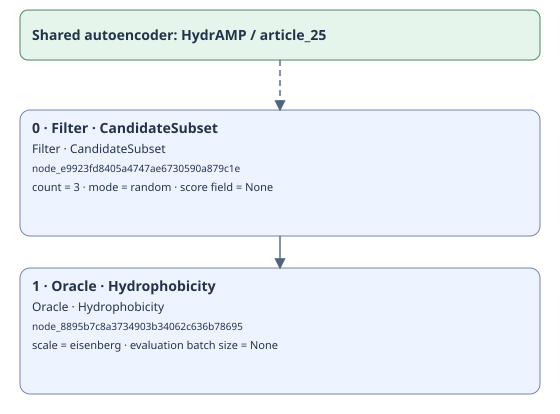

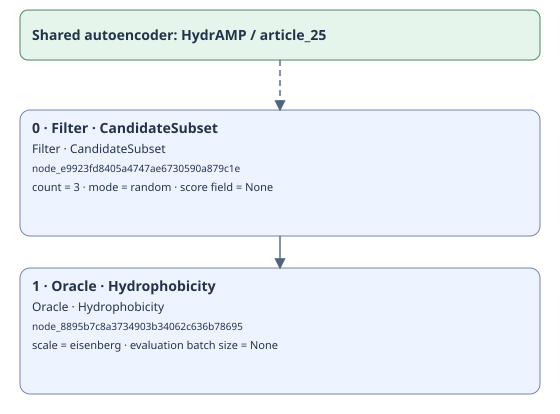

In [17]:
# USAGE: 2. Pass the complete ordered component list.
constructed = Pipeline(
    ## Insert list of objects 
    [
        ps.filters.CandidateSubset(count=3), 
        ps.oracles.Hydrophobicity()
    ],
    autoencoder=ae.HydrAMP(jacobian_mode="approx"),
)
## Display graph before build
display(constructed.show())
## Build object 
compiled_constructed = constructed.build()
## Display builded object 
display(compiled_constructed.show())

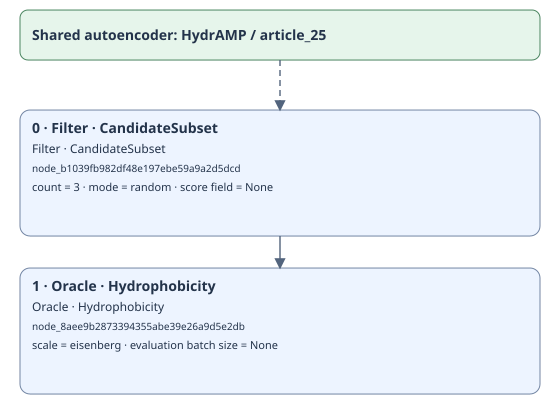

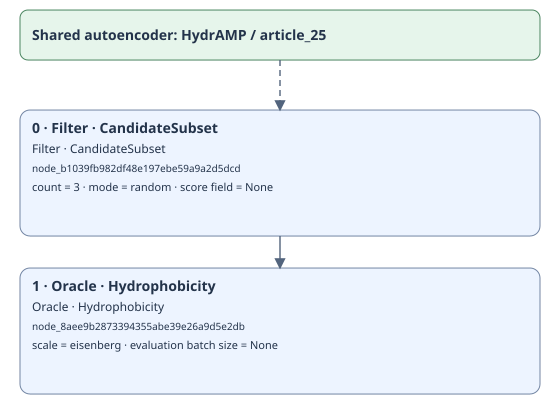

In [18]:
# USAGE: 3. Collect components with a standalone builder.
builder = PipelineBuilder(autoencoder=ae.HydrAMP(jacobian_mode="approx"))   # create pipeline 
builder.add(ps.filters.CandidateSubset(count=3))                            # add component (step 0)
builder.add(ps.oracles.Hydrophobicity())                                    # ad component (step 1)

##  REMARK: Here we need insert schema from builder
from_builder = Pipeline.from_schema(builder.schema)

## Display graph before build
display(from_builder.show())
## Build object 
compiled_from_builder = builder.build()
## Display builded object 
display(compiled_from_builder.show())


assert [node.to_config() for node in builder.schema.steps] == [node.to_config() for node in constructed.to_schema().steps]

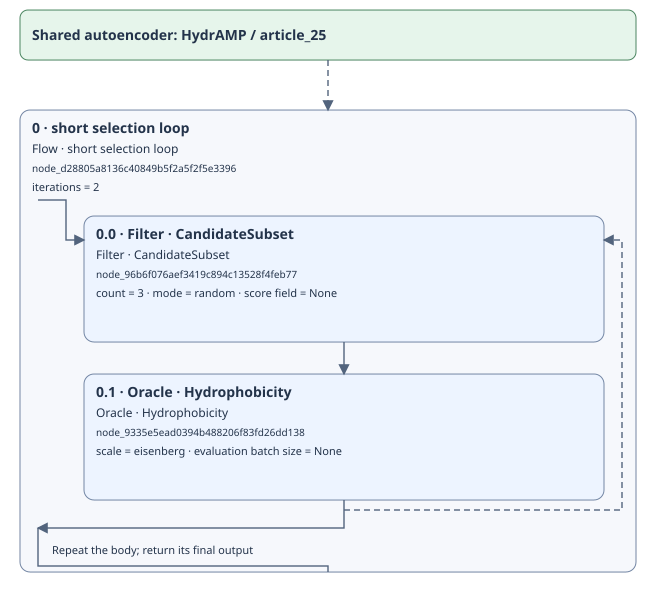

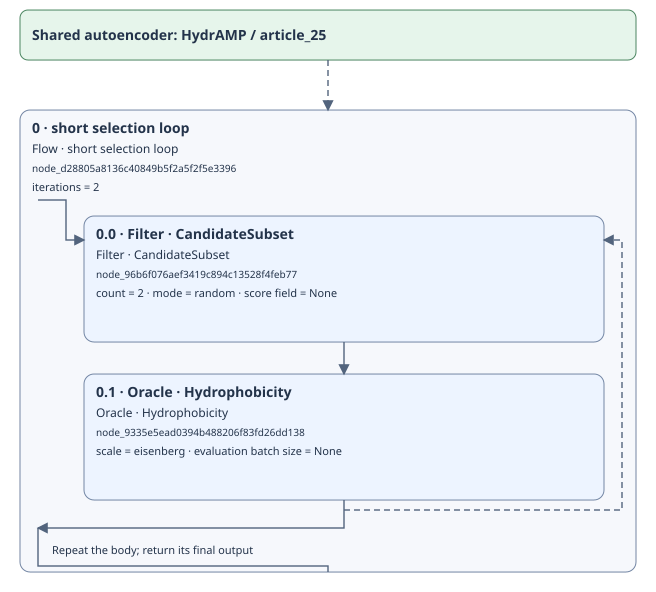

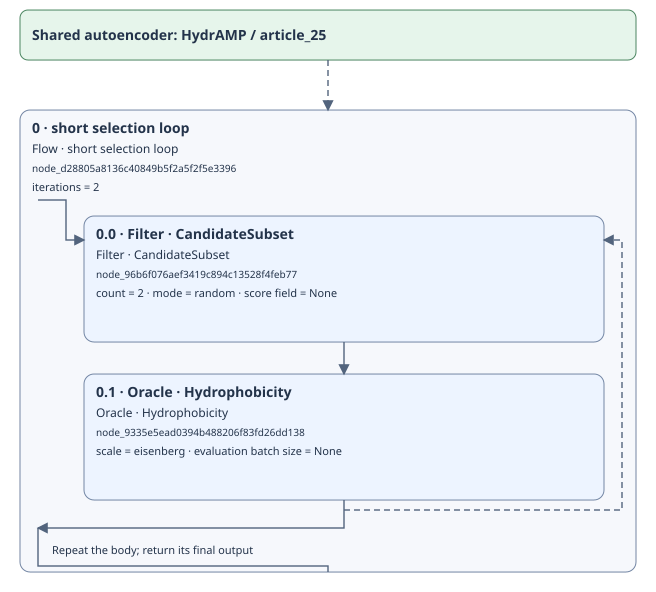

In [19]:
# USAGE: Insert, replace and remove by stable ID before rebuilding.

## Creation of initial `Pipeline``
editable = Pipeline(autoencoder=ae.HydrAMP(jacobian_mode="approx"))
with editable.loop(iterations=2, name="short selection loop") as body:
    stable_id = body.add(ps.filters.CandidateSubset(count=3))
    body.add(ps.oracles.Hydrophobicity())
display(editable.show())

## Methods
### Obtain information about component in `node_id`
editable.describe_component(node_id=stable_id)
### Insertion
inserted_id = editable.insert_component(ps.filters.Deduplicate(), before=stable_id)
### Replacement 
editable.replace_component(stable_id, ps.filters.CandidateSubset(count=2))
### Removing 
editable.remove_component(inserted_id)


display(editable.show())
compiled_editable = editable.build()
display(compiled_editable.show())

## Runner defaults and per-run overrides

### Relation between components (`optimization`)

#### Run construction and object responsibilities

`Pipeline.run()` merges the pipeline’s immutable runner settings with overrides supplied for this run. If the declaration and device have not changed, it reuses the compiled graph.

Each run creates fresh run-specific objects:

| Object | Responsibility |
| --- | --- |
| `Runner` | Sets random-state boundaries, starts execution and finalizes the run |
| `OptimizationState` | Holds observations, budgets and trust regions shared across iterations |
| `Saver` | Records evaluations and the configured execution data |
| `OptimizationContext` | Gives steps access to the state, saver, random generator and other shared services |
| `ExecutablePipeline` | Encodes starting sequences, prepares the graph and invokes its root step |
| Composite `Step` | Controls the order and traversal of its child steps |

`OptimizationContext` can be scoped for an individual step. Scoped contexts share the run’s `OptimizationState`, so observations and budgets remain available across iterations.

#### Batch flow through the graph

`ExecutablePipeline._run()` encodes the starting sequences, attaches candidate identities, calls `root.precompute(context)` once, and executes the root step.

For a `Flow` containing `CandidateSubset(count=3)` followed by `Hydrophobicity`, the data flow is:

```text
[p0, p1, p2, p3]
    -> encode and attach candidate identities
    -> CandidateBatch (4 rows)
    -> CandidateSubset(count=3)
    -> CandidateBatch (3 selected rows)
    -> Hydrophobicity
    -> CandidateBatch (same 3 rows, with oracle fields)
    -> finalize
    -> RunResult and AnalysisReader
```

Every step receives `(batch, context)` and returns a `CandidateBatch`. `Flow` explicitly passes a child’s returned batch to the next child. `Step.__call__()` wraps `prepare_call()` and `_execute()` with scope handling, lineage tracking, measurements and failure handling.

#### Batch and composite-step behavior

A batch contains ordered sequences, aligned fields and `latent_origins` with shape `(B, D)`, where `B` is the number of rows and `D` is the latent dimension. Selection applies to every aligned field. Changing sequences removes oracle fields that no longer describe those sequences.

After MUTANG, `latent_origins` still refer to the walk points that generated the mutants. They are not automatically replaced with encoder outputs for each mutant.

Composites define how their children receive and return batches:

- `Flow` passes each child’s output to the next child.
- `Loop` feeds the complete body’s output into its next iteration.
- `Parallel` gives each branch the same input.
- `LocalEnumeration` advances its walker, emits mutations around the resulting walk point and continues from the walker output. Walker trajectories and emitted mutations remain separate.

An oracle budget stops subsequent evaluation work; it does not discard an already evaluated batch. `oracle_calls` counts newly evaluated distinct sequences per configured objective, not predictor microbatch calls.

See [Runner](../../src/pep_compass/optimization/engine/runner.py), [Flow](../../src/pep_compass/steps/flow/strategies/sequence.py), and [LocalEnumeration](../../src/pep_compass/steps/flow/strategies/local_enumeration.py).

Racja — zostawiłem placeholder zamiast opisać parametry. Poniżej gotowa treść do wstawienia pod `#### Parameters`:

#### Parameters

<!-- #TODO - to można przenisć do docsów -->

Runner settings are grouped by when they affect a run: `execution` controls computation, `storage` controls retained data, and `results` selects the returned interface. Defaults are shown below. Set persistent defaults with `pipeline.set_runner_settings(...)`; override them for one call with `pipeline.run(...)`. A per-run override does not modify the defaults.

##### Execution

| Parameter | Default | Meaning |
| --- | --- | --- |
| `seed` | `None` | Random seed for the run. `None` leaves the caller’s random state unseeded. |
| `device` | `None` | Device used to prepare resources. `None` uses the device declared by the resource. |
| `oracle_calls` | `None` | Soft limit on newly evaluated distinct sequences across configured objectives. The runner stops further evaluation at a complete-batch boundary after reaching the limit. |
| `generated_candidates` | `None` | Soft limit on generated candidates. The runner stops at a complete-batch boundary after reaching the limit. |
| `max_workers` | `1` | Must remain `1` for a single pipeline run. Run multiple independent jobs through the orchestrator. |

Loop iteration counts belong to the graph, for example `ps.flow.Loop(iterations=...)`; they are not runner settings.

##### Storage

| Parameter | Default | Meaning |
| --- | --- | --- |
| `backend` | `"memory"` | Store the run in memory or in SQLite. |
| `path` | `None` | SQLite output directory. Required when `backend="sqlite"`; must be `None` for memory storage. |
| `flush_every` | `1` | Commit after this many completed step or iteration events. This changes commit frequency, not which evaluations are retained. |
| `reconstruction` | `"none"` | Retain no reconstruction states (`"none"`), supported checkpoints (`"boundaries"`), or step inputs and outputs, walker points and the actual root output (`"trajectories"`). Trajectories include boundaries. |
| `component_data` | `"none"` | Retain no optional component artifacts (`"none"`), compact display metadata (`"summary"`), or metadata and supported output-field artifacts (`"full"`). |
| `metrics_level` | `"basic"` | `"none"` retains execution identities and statuses; `"basic"` also records counts, durations and sampled process RSS; `"basic_and_components"` additionally records instrumented internal stages. |
| `save_lineage` | `True` | Retain candidate order and provenance relations. Set to `False` to omit lineage data. |

`reconstruction="trajectories"` is needed to read the actual final graph batch. `Snapshot(...)` requires at least `"boundaries"`. Process RSS is sampled memory, not VRAM or an exact peak allocation.

##### Results

| Parameter | Default | Meaning |
| --- | --- | --- |
| `return_mode` | `"result"` | Return a `RunResult` with its summary and reader (`"result"`), the `AnalysisReader` directly (`"reader"`), or the persistent output path (`"path"`). `"path"` requires SQLite storage. |

For example, set defaults once with `pipeline.set_runner_settings(execution={"oracle_calls": 50})`. Apply overrides to one call with `pipeline.run(sequences, execution={"oracle_calls": 10}, storage={"reconstruction": "trajectories"}, seed=42)`. The call uses `seed=42` for that run and leaves the configured defaults unchanged.

### Results schema

`execution` controls the seed, device and soft budgets. `storage` independently controls measurements, lineage, artifacts and reconstruction. `results.return_mode` selects the public result view; it does not determine which facts are retained. Per-run overrides do not change the wrapper’s defaults.

Every actual evaluation is retained in one `evaluations` table. Repeated candidates reuse the run-local cache. The evaluated archive can include sequences removed by later selection. The final graph batch is separate and is readable when `reconstruction="trajectories"` retained it. The batch is referenced rather than copied into another terminal-results table.

`step_executions` stores invocation status and basic measurements. `iterations` stores nested iteration summaries. `execution_metrics` stores optional aggregated internal stages. `component_records` stores component descriptions and artifacts; it is not the timing or memory table. `batch_members` and `batch_lineage` record order and provenance. Checkpoints retain supported input, state and RNG boundaries for explicit replay.

See [the run-data contract](../run-data-contract.md) and the [reader tutorial](reader_tutorial.ipynb).

### Cells

The construction cell sets execution defaults; the following cell sets storage and one result mode. The short runs compare base retention, detailed metrics with trajectories and replay, persistent SQLite output, and a bounded LE-BO example.

`basic` metrics are independent of optional component artifacts. `basic_and_components` additionally measures instrumented internal stages. Memory measurements are sampled process RSS, not exact allocations or VRAM.

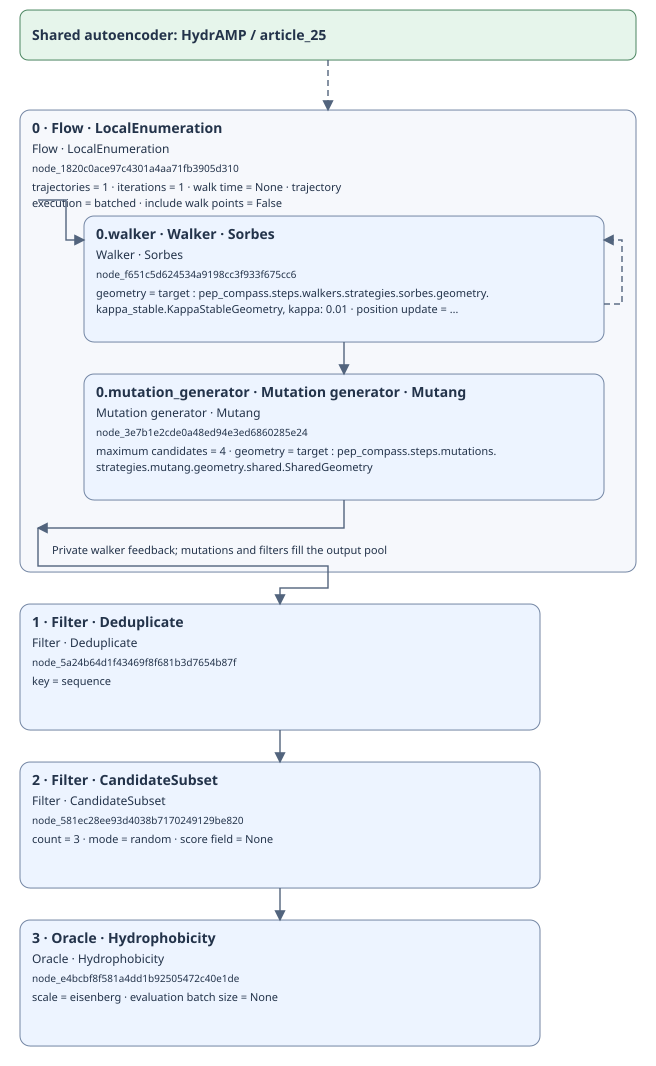

In [20]:
# Pipeline construction
pipeline = Pipeline(
    [
        ps.flow.LocalEnumeration(
            walker=ps.walkers.Sorbes(), mutation_generator=ps.mutations.Mutang(maximum_candidates=4),
            trajectories=1, iterations=1, include_walk_points=False,
        ),
        ps.filters.Deduplicate(), ps.filters.CandidateSubset(count=3), ps.oracles.Hydrophobicity(),
    ],
    autoencoder=ae.HydrAMP(jacobian_mode="approx"),
)

# USAGE: set runner settings (execution part - params used during computation) 
pipeline.set_runner_settings(execution={
    "seed": 7,                      # USAGE: deterministic run seed; default None.
    "device": "cpu",                # USAGE: resource device; default None uses the resource declaration.
    "oracle_calls": 3,              # REMARK: complete-batch threshold; default None is unbounded.
    "generated_candidates": None,   # Default None; local allocation caps belong to ps.mutations.Mutang.
    "max_workers": 1,               # Default and supported value 1; independent jobs use the orchestrator.
})
compiled = pipeline.build()
display(compiled.show())

In [8]:
# USAGE: Configure retention and measurement independently; defaults are stated below.
pipeline.set_runner_settings(storage={
    "backend": "memory",        # Default memory; sqlite persists one run directory.
    "path": None,               # Default None; required for sqlite, absent for memory.
    "flush_every": 1,           # Default 1: commit completed step/iteration events.
    "reconstruction": "none",   # Default none; boundaries or trajectories retain replay data.
    "component_data": "none",   # Default none; summary/full retain optional component artifacts.
    "metrics_level": "basic",   # Default basic; none or basic_and_components select other levels.
    "save_lineage": True,       # Default True: retain ordered provenance relations.
})
# REMARK: Select one return_mode. Repeating a dictionary key silently keeps only its last value.
pipeline.set_runner_settings(results={
    "return_mode": "result",    # Default result: RunResult with summary and reader.
})
# USAGE: return_mode="reader" returns the same result's AnalysisReader.
# USAGE: return_mode="path" returns the run directory and requires SQLite storage.
# REMARK: Snapshot("label") requires boundaries or trajectories retention.

In [9]:
# define input and run 
inputs = ["FLYKWWIRIGRLKL"]
base_result = pipeline.run(inputs)

# display summary of run
display(base_result.reader.get_archive())
display(base_result.summary)
assert base_result.summary["oracle_calls"] == 3

,evaluation_id,objective,sequence,score,direction,evaluation_index,candidate_id,execution_id,iteration_id
0,1,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,0,3,11,None
1,2,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,1,4,11,None
2,3,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,2,5,11,None


{'status': 'completed',
 'duration_seconds': 1.7690380999993067,
 'oracle_calls': 3,
 'generated_candidates': 4,
 'completed_iterations': 1,
 'iteration_events': 1,
 'objective_name': 'hydrophobicity',
 'terminal_count': 3,
 'error': None,
 'best_sequence': 'FLYKWWIRIGRLWL',
 'best_score': 0.28357142857142853}

In [10]:
# USAGE: Retain trajectories and explicitly request detailed execution measurements.
import pandas as pd

retained_result = pipeline.run(inputs, storage={
    "reconstruction": "trajectories",
    "component_data": "summary",
    "metrics_level": "basic_and_components",
    "save_lineage": True,
})

# Observation data
## USAGE: Evaluations are mandatory; component data contains descriptive metadata.
display(retained_result.reader.get_evaluations())
display(retained_result.reader.get_component_data())

# Execution measurements
## USAGE: Read time, counts and sampled process memory from their actual SQL tables.
for table_name in ("step_executions", "iterations", "execution_metrics"):
    table = retained_result.reader.tables[table_name]
    measured = pd.concat(table.scan(table.columns, chunk_size=100), ignore_index=True)
    display(measured)
# REMARK: Component descriptions do not contain the measurement columns shown above.

# Explicit reconstruction
checkpoint = int(retained_result.reader.get_checkpoints().iloc[0]["checkpoint_id"])
assert retained_result.reader.reconstruct_local_enumeration(checkpoint).matches
points, latent_positions = retained_result.reader.get_trajectories()
display(points)
assert len(points) == len(latent_positions)

,evaluation_id,objective,sequence,score,direction,evaluation_index,candidate_id,execution_id,iteration_id
0,1,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,0,3,11,None
1,2,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,1,4,11,None
2,3,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,2,5,11,None


,record_id,node_id,execution_id,name,payload_id,data
0,1,node_5b33875f11e4490eb28b598c41731f85,6,Sorbes,4148b708c682ca41f3d9722911b519949d114adc9d2818...,{'geometry': {'_target_': 'pep_compass.steps.w...
1,2,node_d02a19f7ecfa4a31ba1b18975df7c582,7,Mutang,0acce1925ae47f42557e8b95729ea45ae251e8ed7a8d6b...,"{'maximum_candidates': 4, 'geometry': {'_targe..."
2,3,node_a92fef982cd34add8ece351ac6bfdf65,8,Flow,748f9502391386d7c90056bd76194f86f237ea8dc88633...,{}
3,4,node_a92fef982cd34add8ece351ac6bfdf65,5,LocalEnumeration,fec2659a4f24309efc2cfe51aaf99f3f0d54583462fb2b...,"{'trajectories': 1, 'iterations': 1, 'walk_tim..."
4,5,node_abd0890c8e2c40af819c339ba3819f73,9,Deduplicate,714d6f4feb5c4a885c5698b5d7c9212f2bc512ff987872...,{'key': 'sequence'}
5,6,node_12ef993bf20a4b6a9bbf365413c88f75,10,CandidateSubset,b475e97980e05055eceda2b8384731da31ebcfbfa90b4f...,"{'count': 3, 'mode': 'random', 'score_field': ..."
6,7,node_221fe248b53a4b32ac91af844f23a9a8,11,Hydrophobicity,f1c09745416001ca731b8e3a7376af24a95a50bbfe391f...,"{'scale': 'eisenberg', 'evaluation_batch_size'..."
7,8,None,4,Flow,748f9502391386d7c90056bd76194f86f237ea8dc88633...,{}


,execution_id,node_id,parent_execution_id,iteration_id,input_batch_id,output_batch_id,scope_json,input_count,output_count,duration_seconds,memory_start_bytes,memory_peak_bytes,memory_end_bytes,status,phase,error
0,0,root,NaN,NaN,NaN,NaN,"{""path"": [], ""loop_indices"": [], ""branch_names...",NaN,NaN,0.000511,638152704,638152704,638152704,completed,precompute,None
1,1,node_a92fef982cd34add8ece351ac6bfdf65,0.0,NaN,NaN,NaN,"{""path"": [""LocalEnumeration""], ""loop_indices"":...",NaN,NaN,0.000182,638152704,638152704,638152704,completed,precompute,None
2,2,node_a92fef982cd34add8ece351ac6bfdf65,1.0,NaN,NaN,NaN,"{""path"": [""LocalEnumeration"", ""Flow""], ""loop_i...",NaN,NaN,0.000044,638152704,638152704,638152704,completed,precompute,None
3,3,node_221fe248b53a4b32ac91af844f23a9a8,0.0,NaN,NaN,NaN,"{""path"": [""Hydrophobicity""], ""loop_indices"": [...",NaN,NaN,0.000131,638152704,638152704,638152704,completed,precompute,None
4,4,root,NaN,NaN,1.0,8.0,"{""path"": [""Flow""], ""loop_indices"": [], ""branch...",1.0,3.0,0.889480,638152704,645644288,645644288,completed,execute,None
5,5,node_a92fef982cd34add8ece351ac6bfdf65,4.0,NaN,1.0,5.0,"{""path"": [""Flow"", ""LocalEnumeration""], ""loop_i...",1.0,4.0,0.875830,638152704,645640192,645640192,completed,execute,None
6,6,node_5b33875f11e4490eb28b598c41731f85,5.0,1.0,2.0,3.0,"{""path"": [""Flow"", ""LocalEnumeration"", ""branch[...",1.0,1.0,0.694418,638152704,640114688,640114688,completed,execute,None
7,7,node_d02a19f7ecfa4a31ba1b18975df7c582,5.0,1.0,3.0,4.0,"{""path"": [""Flow"", ""LocalEnumeration"", ""branch[...",1.0,4.0,0.058608,640122880,643559424,643559424,completed,execute,None
8,8,node_a92fef982cd34add8ece351ac6bfdf65,5.0,1.0,4.0,4.0,"{""path"": [""Flow"", ""LocalEnumeration"", ""branch[...",4.0,4.0,0.043744,643846144,645640192,645640192,completed,execute,None
9,9,node_abd0890c8e2c40af819c339ba3819f73,4.0,NaN,5.0,6.0,"{""path"": [""Flow"", ""Deduplicate""], ""loop_indice...",4.0,4.0,0.002232,645640192,645640192,645640192,completed,execute,None


,iteration_id,loop_execution_id,parent_iteration_id,node_id,iteration_index,scope_json,trajectories,elapsed_seconds,duration_seconds,interval_seconds,step_duration_sum_seconds,memory_start_bytes,memory_peak_bytes,memory_end_bytes,input_count,output_count,status
0,1,5,None,node_a92fef982cd34add8ece351ac6bfdf65,0,"{""path"": [""Flow"", ""LocalEnumeration"", ""branch[...",1,1.430799,0.871426,None,0.79677,638152704,645640192,645640192,1,4,completed


,metric_id,execution_id,iteration_id,stage_name,duration_seconds,memory_start_bytes,memory_peak_bytes,memory_end_bytes,input_count,output_count,status
0,1,6,1.0,input_geometry,0.091055,638152704,639455232,639455232,1,1.0,completed
1,2,6,1.0,directions,0.000294,639520768,639520768,639520768,1,1.0,completed
2,3,6,1.0,scaling,0.000167,639520768,639520768,639520768,1,1.0,completed
3,4,6,1.0,acceleration,0.010338,639520768,639520768,639520768,1,1.0,completed
4,5,6,1.0,position_update,0.002109,639520768,639520768,639520768,1,1.0,completed
5,6,6,1.0,boundary,0.000134,639520768,639520768,639520768,1,1.0,completed
6,7,6,1.0,output_geometry,0.485375,639520768,640032768,640032768,1,1.0,completed
7,8,7,1.0,geometry,0.000063,640122880,640122880,640122880,1,1.0,completed
8,9,7,1.0,directions,0.000209,640122880,640122880,640122880,1,NaN,completed
9,10,7,1.0,scoring,0.000146,640122880,640122880,640122880,1,NaN,completed


,execution_id,sequence,latent_index,trajectory_id,trajectory_index,trajectory_step,candidate_id
0,6,FLYKWWIRIGRLKL,0,Flow/LocalEnumeration/branch[batched_trajector...,0,0,1


In [11]:
# USAGE: Change the storage destination while keeping the retained-data contract explicit.
artifacts = TemporaryDirectory(prefix="pep-compass-tutorial-")
run_path = Path(artifacts.name) / "sqlite-run"
disk_result = pipeline.run(inputs, storage={
    "backend": "sqlite",
    "path": str(run_path),
    "reconstruction": "trajectories",
    "component_data": "summary",
    "metrics_level": "basic_and_components",
    "save_lineage": True,
})
display(disk_result.reader.get_archive())
display(disk_result.summary)
assert (run_path / "settings.json").is_file()
assert (run_path / "results.sqlite").is_file()
assert len(disk_result.reader.get_final_batch()) == disk_result.summary["terminal_count"]
# REMARK: The path is a directory containing both files, not the SQLite filename alone.

,evaluation_id,objective,sequence,score,direction,evaluation_index,candidate_id,execution_id,iteration_id
0,1,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,0,3,11,None
1,2,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,1,4,11,None
2,3,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,2,5,11,None


{'status': 'completed',
 'duration_seconds': 2.0675314999971306,
 'oracle_calls': 3,
 'generated_candidates': 4,
 'completed_iterations': 1,
 'iteration_events': 1,
 'objective_name': 'hydrophobicity',
 'terminal_count': 3,
 'error': None,
 'best_sequence': 'FLYKWWIRIGRLWL',
 'best_score': 0.28357142857142853}

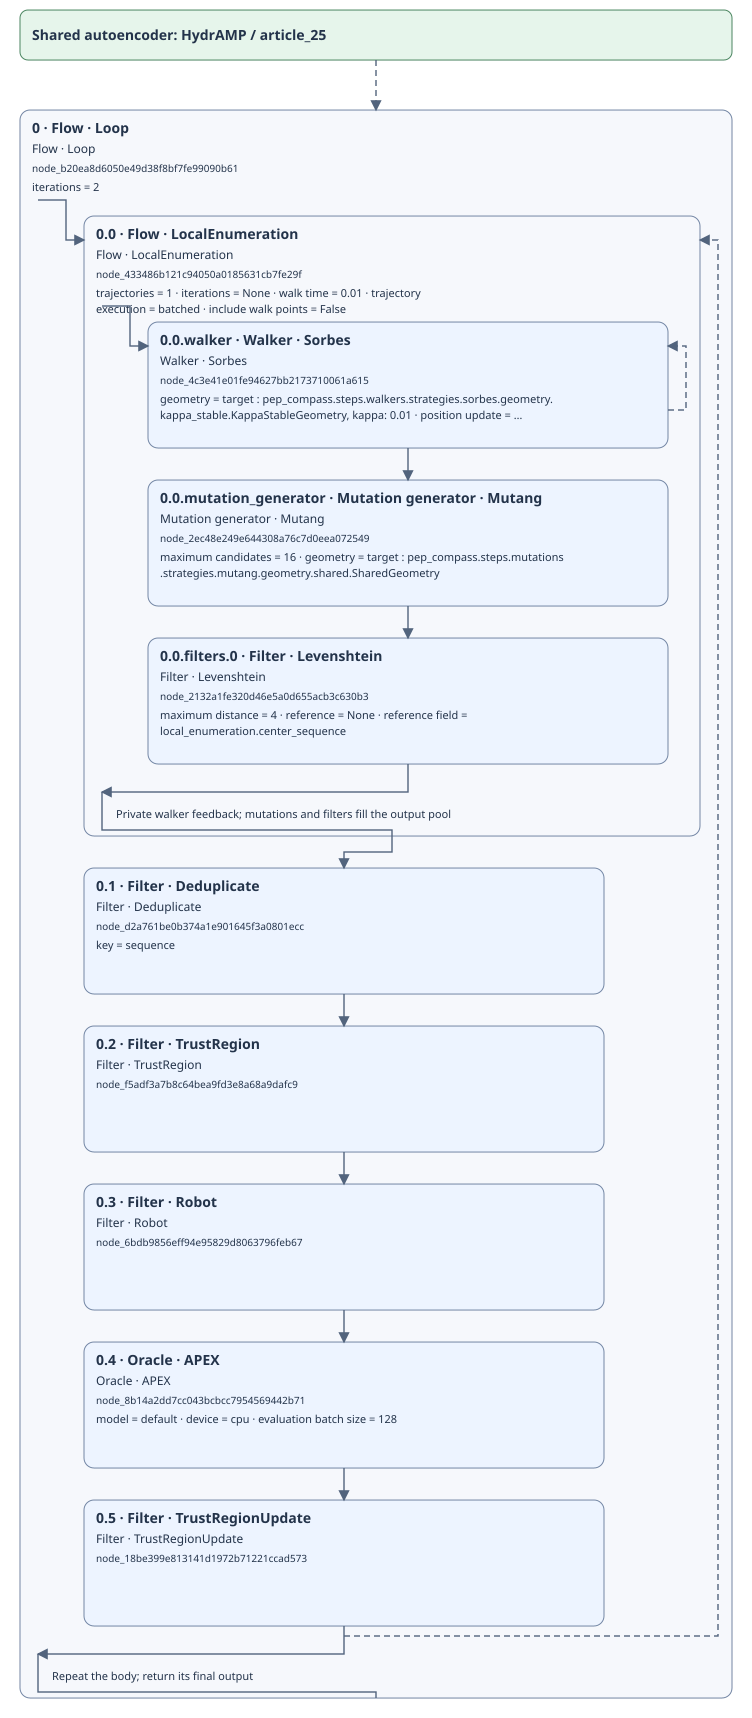

,evaluation_id,objective,sequence,score,direction,evaluation_index,candidate_id,execution_id,iteration_id
0,1,apex,FLYWWWFRIGRLWL,5.246353,minimize,0,11,17,1
1,2,apex,FLYWWWIRIGRLWL,4.640906,minimize,1,15,17,1
2,3,apex,FLYWWWIRPGRLWL,5.850920,minimize,2,17,17,1


{'status': 'completed',
 'duration_seconds': 7.966208500001812,
 'oracle_calls': 3,
 'generated_candidates': 16,
 'completed_iterations': 2,
 'iteration_events': 2,
 'objective_name': 'apex',
 'terminal_count': 3,
 'error': None,
 'best_sequence': 'FLYWWWIRIGRLWL',
 'best_score': 4.640905857086182}

In [12]:
# USAGE: Load a predefined composition using the same public Step constructors.
from pep_compass.predefined import lebo

# Construction
## REMARK: LE-BO means Local Enumeration with Bayesian Optimization.
## The preset combines generation, selection, an APEX oracle and trust-region updates.
optimization_pipeline = lebo(
    device="cpu", seed=7, mutation_candidates=16, oracle_calls=3,
    iterations=2, trajectories=1, walk_time=0.01,
)

# Validation and execution
optimization_pipeline.validate()
display(optimization_pipeline.show())
bayesian_result = optimization_pipeline.run(inputs)
# REMARK: This result variable is retained for the original, unchanged cleanup cell.
display(bayesian_result.reader.get_archive())
display(bayesian_result.summary)
assert bayesian_result.summary["oracle_calls"] >= 1

## Persistence and analysis

A persistent run is a directory containing `results.sqlite` and `settings.json`. The settings record the resolved graph, input, seed, runner settings and model/code provenance. Memory storage has the same SQL schema; `RunResult.save()` exports retained data without another computation. Exporting a CSV preserves one table, not latent payloads or replay state.

The next cell opens an exported run, scans selected columns, discovers a collection, and exports an evaluated table. Its output follows the same contracts as the writer. For an independent walkthrough of evaluated versus final candidates, lineage, metrics, component artifacts, supported reconstruction, missing-data errors and collection filtering, continue with [reader_tutorial.ipynb](reader_tutorial.ipynb).

In [13]:
from pep_compass.optimization.saving import AnalysisReader
from pep_compass.analysis.reader import ExperimentReader

exported_path = base_result.save(Path(artifacts.name) / "exported-memory")
with AnalysisReader(exported_path) as reader:
    display(reader.get_archive())
    display(reader.get_metadata()["summary"])
    for chunk in reader.tables["evaluation_archive"].scan(["sequence", "score"], chunk_size=2):
        display(chunk)

collection = ExperimentReader(artifacts.name)
display(collection.select(seeds=[7]).collect("evaluation_archive", columns=["sequence", "score", "seed"]))
base_result.reader.get_archive().to_csv(Path(artifacts.name) / "evaluated.csv", index=False)
pipeline.save_schema(Path(artifacts.name) / "pipeline.json")

,evaluation_id,objective,sequence,score,direction,evaluation_index,candidate_id,execution_id,iteration_id
0,1,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,0,3,11,None
1,2,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,1,4,11,None
2,3,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,2,5,11,None


{'status': 'completed',
 'duration_seconds': 1.7690380999993067,
 'oracle_calls': 3,
 'generated_candidates': 4,
 'completed_iterations': 1,
 'iteration_events': 1,
 'objective_name': 'hydrophobicity',
 'terminal_count': 3,
 'error': None,
 'best_sequence': 'FLYKWWIRIGRLWL',
 'best_score': 0.28357142857142853}

,sequence,score
0,FLYKWWIRIGRLWL,0.283571
1,FLYKWWPRIGRLKL,0.027143


,sequence,score
0,FLYKWWPRIGRLWL,0.192143


,sequence,score,seed
0,FLYKWWIRIGRLWL,0.283571,7
1,FLYKWWPRIGRLKL,0.027143,7
2,FLYKWWPRIGRLWL,0.192143,7
3,FLYKWWIRIGRLWL,0.283571,7
4,FLYKWWPRIGRLKL,0.027143,7
5,FLYKWWPRIGRLWL,0.192143,7


PosixPath('/tmp/pep-compass-tutorial-5z63i6sm/pipeline.json')

## The same constructors in Hydra

A YAML `_target_` constructs the same public Python class or preset used here. Hydra composes configuration groups and parameter overrides; it does not implement another computation engine. The orchestrator freezes model-free plans and dispatches independent wrapper calls. Its execution backend is separate from the run's memory/SQLite storage backend.

The next cell only composes and validates a plan. The independent [orchestrator_tutorial.ipynb](orchestrator_tutorial.ipynb) creates real temporary YAML, CSV, FASTA and Slurm-template files, demonstrates overrides, runs local and subprocess jobs, and generates a server-profile script without submitting a scheduler job.

In [14]:
from pep_compass.orchestrator.configuration import compose_configuration
from pep_compass.orchestrator.planning import plan_configuration

configuration = compose_configuration(["pipeline=simple", "pipeline.mutation_candidates=8"])
plan = plan_configuration(configuration)
assert plan.schema.steps[0].children["mutation_generator"].parameters["maximum_candidates"] == 8
print("Planned independent jobs:", len(plan.entries))
# REMARK: Orchestrator().run(plan) dispatches the jobs; this cell only plans.

Planned independent jobs: 1


In [15]:
# USAGE: Close results before cleaning up temporary output directories.
for result in (base_result, retained_result, disk_result, bayesian_result):
    result.close()
artifacts.cleanup()